In [ ]:
import numpy as np

# Given documents
docs = [
    "mildew affects tomatoes",
    "mildew affects potatoes",
    "sun affects tomatoes",
    "tomatoes grow in sun and rain",
    "potatoes need sun"
]

query = "mildew tomatoes"

print("DEEP LEARNING - CHAPTER 4")
print("SET A - QUESTION 1")
print("TF-IDF + DOCUMENT SEARCH")
print("-" * 40)

for i, doc in enumerate(docs, start=1):
    print(f"Document {i}: {doc}")

print("\nSearch Query:", query)

DEEP LEARNING - CHAPTER 4
SET A - QUESTION 1
TF-IDF + DOCUMENT SEARCH
----------------------------------------
Document 1: mildew affects tomatoes
Document 2: mildew affects potatoes
Document 3: sun affects tomatoes
Document 4: tomatoes grow in sun and rain
Document 5: potatoes need sun

Search Query: mildew tomatoes


In [ ]:
# TASK (a): Stopword Removal and Vocabulary Creation

# Define stopwords
stopwords = {"and", "in"}

# Tokenize documents and remove stopwords
tokenized_docs = []

for doc in docs:
    words = doc.lower().split()
    filtered_words = [word for word in words if word not in stopwords]
    tokenized_docs.append(filtered_words)

print("DOCUMENTS AFTER STOPWORD REMOVAL")
print("-" * 45)

for i, tokens in enumerate(tokenized_docs, start=1):
    print(f"Document {i}: {tokens}")

DOCUMENTS AFTER STOPWORD REMOVAL
---------------------------------------------
Document 1: ['mildew', 'affects', 'tomatoes']
Document 2: ['mildew', 'affects', 'potatoes']
Document 3: ['sun', 'affects', 'tomatoes']
Document 4: ['tomatoes', 'grow', 'sun', 'rain']
Document 5: ['potatoes', 'need', 'sun']


In [ ]:
# TASK (a): Vocabulary Creation

vocab = sorted(set(
    word
    for doc in tokenized_docs
    for word in doc
))

print("FINAL VOCABULARY")
print("-" * 45)

print("Vocabulary:", vocab)
print("Vocabulary Size:", len(vocab))

print("\nVocabulary with Index:")
for index, word in enumerate(vocab):
    print(f"{index}: {word}")

FINAL VOCABULARY
---------------------------------------------
Vocabulary: ['affects', 'grow', 'mildew', 'need', 'potatoes', 'rain', 'sun', 'tomatoes']
Vocabulary Size: 8

Vocabulary with Index:
0: affects
1: grow
2: mildew
3: need
4: potatoes
5: rain
6: sun
7: tomatoes


In [ ]:
# TASK (b) - SUBTASK B1: TERM FREQUENCY

N = len(tokenized_docs)
V = len(vocab)

TF = np.zeros((N, V))

for i, doc in enumerate(tokenized_docs):
    for j, word in enumerate(vocab):
        TF[i, j] = doc.count(word) / len(doc)

print("TERM FREQUENCY (TF) MATRIX")
print("-" * 50)

print("Vocabulary:", vocab)
print(np.round(TF, 3))

print("\nTF Matrix Shape:", TF.shape)

TERM FREQUENCY (TF) MATRIX
--------------------------------------------------
Vocabulary: ['affects', 'grow', 'mildew', 'need', 'potatoes', 'rain', 'sun', 'tomatoes']
[[0.333 0.    0.333 0.    0.    0.    0.    0.333]
 [0.333 0.    0.333 0.    0.333 0.    0.    0.   ]
 [0.333 0.    0.    0.    0.    0.    0.333 0.333]
 [0.    0.25  0.    0.    0.    0.25  0.25  0.25 ]
 [0.    0.    0.    0.333 0.333 0.    0.333 0.   ]]

TF Matrix Shape: (5, 8)


In [ ]:
# TASK (b) - SUBTASK B2: INVERSE DOCUMENT FREQUENCY

DF = np.zeros(V)

for j, word in enumerate(vocab):
    DF[j] = sum(word in doc for doc in tokenized_docs)

IDF = np.log(N / DF)

print("DOCUMENT FREQUENCY (DF)")
print("-" * 50)

for word, df, idf in zip(vocab, DF, IDF):
    print(f"{word:12s} DF = {int(df)} | IDF = {idf:.3f}")

DOCUMENT FREQUENCY (DF)
--------------------------------------------------
affects      DF = 3 | IDF = 0.511
grow         DF = 1 | IDF = 1.609
mildew       DF = 2 | IDF = 0.916
need         DF = 1 | IDF = 1.609
potatoes     DF = 2 | IDF = 0.916
rain         DF = 1 | IDF = 1.609
sun          DF = 3 | IDF = 0.511
tomatoes     DF = 3 | IDF = 0.511


In [ ]:
# TASK (b) - SUBTASK B3: TF-IDF MATRIX

TFIDF = TF * IDF

print("FINAL TF-IDF MATRIX")
print("-" * 65)

print("Vocabulary Order:")
print(vocab)

print("\nTF-IDF Values:")
print(np.round(TFIDF, 3))

print("\nTF-IDF Matrix Shape:", TFIDF.shape)

FINAL TF-IDF MATRIX
-----------------------------------------------------------------
Vocabulary Order:
['affects', 'grow', 'mildew', 'need', 'potatoes', 'rain', 'sun', 'tomatoes']

TF-IDF Values:
[[0.17  0.    0.305 0.    0.    0.    0.    0.17 ]
 [0.17  0.    0.305 0.    0.305 0.    0.    0.   ]
 [0.17  0.    0.    0.    0.    0.    0.17  0.17 ]
 [0.    0.402 0.    0.    0.    0.402 0.128 0.128]
 [0.    0.    0.    0.536 0.305 0.    0.17  0.   ]]

TF-IDF Matrix Shape: (5, 8)


In [ ]:
# TASK (c): COMPUTE QUERY TF-IDF VECTOR

# Step 1: Tokenize query and remove stopwords
query_tokens = [
    word for word in query.lower().split()
    if word not in stopwords
]

# Step 2: Compute query TF
query_tf = np.zeros(V)

for j, word in enumerate(vocab):
    query_tf[j] = query_tokens.count(word) / len(query_tokens)

# Step 3: Compute query TF-IDF
# Reuse IDF values calculated from the documents
query_tfidf = query_tf * IDF

# Step 4: Display results
print("TASK (c): QUERY TF-IDF VECTOR")
print("-" * 50)

print("Original Query:", query)
print("Query Tokens:", query_tokens)

print("\nVocabulary:", vocab)

print("\nQuery TF Vector:")
print(np.round(query_tf, 3))

print("\nQuery TF-IDF Vector:")
print(np.round(query_tfidf, 3))

print("\nVector Shape:", query_tfidf.shape)

TASK (c): QUERY TF-IDF VECTOR
--------------------------------------------------
Original Query: mildew tomatoes
Query Tokens: ['mildew', 'tomatoes']

Vocabulary: ['affects', 'grow', 'mildew', 'need', 'potatoes', 'rain', 'sun', 'tomatoes']

Query TF Vector:
[0.  0.  0.5 0.  0.  0.  0.  0.5]

Query TF-IDF Vector:
[0.    0.    0.458 0.    0.    0.    0.    0.255]

Vector Shape: (8,)


In [ ]:
# TASK (d): COSINE SIMILARITY AND DOCUMENT RANKING

import numpy as np

# Subtask D1: Cosine similarity function
def cosine_similarity(a, b):

    numerator = np.dot(a, b)

    denominator = np.linalg.norm(a) * np.linalg.norm(b)

    if denominator == 0:
        return 0.0

    return numerator / denominator


# Subtask D2: Calculate similarity for all documents
similarities = np.array([
    cosine_similarity(query_tfidf, doc_vector)
    for doc_vector in TFIDF
])

print("COSINE SIMILARITY SCORES")
print("-" * 50)

for i, score in enumerate(similarities, start=1):
    print(f"Document {i}: {score:.4f}")


# Subtask D3: Rank documents
ranked_indices = np.argsort(-similarities)

print("\nRANKED DOCUMENTS (MOST TO LEAST RELEVANT)")
print("-" * 60)

for rank, idx in enumerate(ranked_indices, start=1):
    print(f"Rank {rank}")
    print(f"Document {idx + 1}: {docs[idx]}")
    print(f"Cosine Similarity: {similarities[idx]:.4f}")
    print("-" * 40)

COSINE SIMILARITY SCORES
--------------------------------------------------
Document 1: 0.8991
Document 2: 0.5746
Document 3: 0.2811
Document 4: 0.1042
Document 5: 0.0000

RANKED DOCUMENTS (MOST TO LEAST RELEVANT)
------------------------------------------------------------
Rank 1
Document 1: mildew affects tomatoes
Cosine Similarity: 0.8991
----------------------------------------
Rank 2
Document 2: mildew affects potatoes
Cosine Similarity: 0.5746
----------------------------------------
Rank 3
Document 3: sun affects tomatoes
Cosine Similarity: 0.2811
----------------------------------------
Rank 4
Document 4: tomatoes grow in sun and rain
Cosine Similarity: 0.1042
----------------------------------------
Rank 5
Document 5: potatoes need sun
Cosine Similarity: 0.0000
----------------------------------------


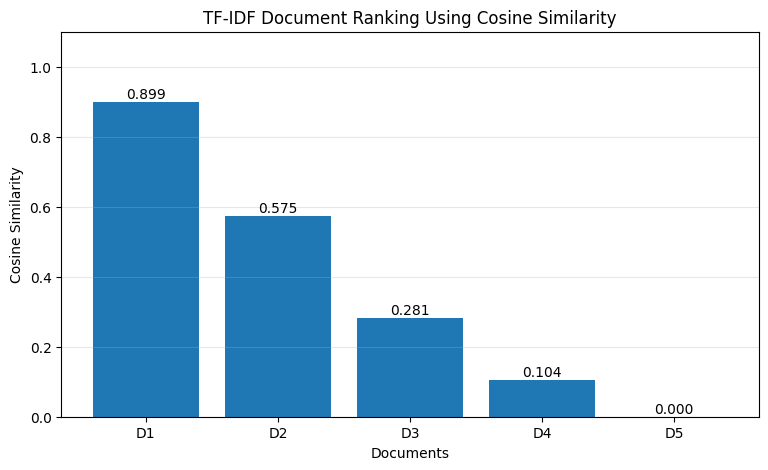

In [ ]:
# TASK (d): VISUALIZATION

import matplotlib.pyplot as plt

document_labels = ["D1", "D2", "D3", "D4", "D5"]

plt.figure(figsize=(9, 5))

bars = plt.bar(document_labels, similarities)

for bar, score in zip(bars, similarities):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{score:.3f}",
        ha="center"
    )

plt.title("TF-IDF Document Ranking Using Cosine Similarity")
plt.xlabel("Documents")
plt.ylabel("Cosine Similarity")

plt.ylim(0, 1.1)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
# TASK (e): HANDLE UNSEEN WORDS IN QUERY

new_query = "mildew fertilizer"

# Subtask E1: Tokenize new query
new_query_tokens = [
    word for word in new_query.lower().split()
    if word not in stopwords
]

print("TASK (e): UNSEEN QUERY WORD HANDLING")
print("-" * 55)

print("New Query:", new_query)

# Subtask E2: Check vocabulary
for word in new_query_tokens:

    if word in vocab:
        index = vocab.index(word)

        print(f"\nWord: {word}")
        print(f"Status: Present in vocabulary")
        print(f"IDF: {IDF[index]:.3f}")

    else:
        print(f"\nWord: {word}")
        print("Status: Not present in vocabulary")
        print("Document Frequency: 0")
        print("IDF: Undefined (division by zero)")
        print("Effective TF-IDF contribution: 0")


# Subtask E3: Construct query vector
new_query_tf = np.zeros(len(vocab))

for j, word in enumerate(vocab):
    new_query_tf[j] = (
        new_query_tokens.count(word) / len(new_query_tokens)
    )

new_query_tfidf = new_query_tf * IDF

print("\nNEW QUERY TF-IDF VECTOR:")
print(np.round(new_query_tfidf, 3))

TASK (e): UNSEEN QUERY WORD HANDLING
-------------------------------------------------------
New Query: mildew fertilizer

Word: mildew
Status: Present in vocabulary
IDF: 0.916

Word: fertilizer
Status: Not present in vocabulary
Document Frequency: 0
IDF: Undefined (division by zero)
Effective TF-IDF contribution: 0

NEW QUERY TF-IDF VECTOR:
[0.    0.    0.458 0.    0.    0.    0.    0.   ]


In [ ]:
# FINAL VERIFICATION - SET A QUESTION 1

print("=" * 55)
print("SET A - Q1: TF-IDF + DOCUMENT SEARCH")
print("=" * 55)

# Verify vocabulary
assert len(vocab) == 8

# Verify matrix dimensions
assert TF.shape == (5, 8)
assert TFIDF.shape == (5, 8)

# Verify query vector
assert query_tfidf.shape == (8,)

# Verify valid numerical values
assert np.all(np.isfinite(TFIDF))
assert np.all(np.isfinite(query_tfidf))

# Verify highest-ranked document
assert ranked_indices[0] == 0

# Verify descending order
assert np.all(
    similarities[ranked_indices][:-1] >=
    similarities[ranked_indices][1:]
)

print("\nALL VERIFICATION CHECKS PASSED!")

print("\nVocabulary:")
print(vocab)

print("\nFinal TF-IDF Matrix:")
print(np.round(TFIDF, 3))

print("\nQuery TF-IDF Vector:")
print(np.round(query_tfidf, 3))

print("\nRANKED DOCUMENTS:")

for rank, idx in enumerate(ranked_indices, 1):
    print(
        f"Rank {rank}: D{idx+1} "
        f"| Similarity = {similarities[idx]:.4f}"
        f" | {docs[idx]}"
    )

print("\nMOST RELEVANT DOCUMENT:")
print(docs[ranked_indices[0]])

print("\nQ1 IMPLEMENTATION COMPLETED SUCCESSFULLY!")

SET A - Q1: TF-IDF + DOCUMENT SEARCH

ALL VERIFICATION CHECKS PASSED!

Vocabulary:
['affects', 'grow', 'mildew', 'need', 'potatoes', 'rain', 'sun', 'tomatoes']

Final TF-IDF Matrix:
[[0.17  0.    0.305 0.    0.    0.    0.    0.17 ]
 [0.17  0.    0.305 0.    0.305 0.    0.    0.   ]
 [0.17  0.    0.    0.    0.    0.    0.17  0.17 ]
 [0.    0.402 0.    0.    0.    0.402 0.128 0.128]
 [0.    0.    0.    0.536 0.305 0.    0.17  0.   ]]

Query TF-IDF Vector:
[0.    0.    0.458 0.    0.    0.    0.    0.255]

RANKED DOCUMENTS:
Rank 1: D1 | Similarity = 0.8991 | mildew affects tomatoes
Rank 2: D2 | Similarity = 0.5746 | mildew affects potatoes
Rank 3: D3 | Similarity = 0.2811 | sun affects tomatoes
Rank 4: D4 | Similarity = 0.1042 | tomatoes grow in sun and rain
Rank 5: D5 | Similarity = 0.0000 | potatoes need sun

MOST RELEVANT DOCUMENT:
mildew affects tomatoes

Q1 IMPLEMENTATION COMPLETED SUCCESSFULLY!


In [ ]:
import numpy as np

# SET A - QUESTION 2
# MULTI-HEAD SCALED DOT-PRODUCT ATTENTION

# Query Matrix
Q2 = np.array([
    [1, 0, 1, 0],
    [0, 1, 0, 1]
], dtype=float)

# Key Matrix
K2 = np.array([
    [1, 0, 0, 1],
    [0, 1, 1, 0],
    [1, 1, 1, 1]
], dtype=float)

# Value Matrix
V2 = np.array([
    [1, 0],
    [0, 2],
    [2, 2]
], dtype=float)

print("QUERY MATRIX:")
print(Q2)

print("\nKEY MATRIX:")
print(K2)

print("\nVALUE MATRIX:")
print(V2)

print("\nMATRIX SHAPES:")
print("Q shape:", Q2.shape)
print("K shape:", K2.shape)
print("V shape:", V2.shape)

QUERY MATRIX:
[[1. 0. 1. 0.]
 [0. 1. 0. 1.]]

KEY MATRIX:
[[1. 0. 0. 1.]
 [0. 1. 1. 0.]
 [1. 1. 1. 1.]]

VALUE MATRIX:
[[1. 0.]
 [0. 2.]
 [2. 2.]]

MATRIX SHAPES:
Q shape: (2, 4)
K shape: (3, 4)
V shape: (3, 2)


In [ ]:
# TASK (a) and (b): SPLIT INTO TWO HEADS

# Head 1: First two dimensions
Q_head1 = Q2[:, :2]
K_head1 = K2[:, :2]

# Head 2: Last two dimensions
Q_head2 = Q2[:, 2:]
K_head2 = K2[:, 2:]

print("HEAD 1")
print("Q_head1:\n", Q_head1)
print("K_head1:\n", K_head1)

print("\nHEAD 2")
print("Q_head2:\n", Q_head2)
print("K_head2:\n", K_head2)

print("\nDimensions per head:", Q_head1.shape[1])

HEAD 1
Q_head1:
 [[1. 0.]
 [0. 1.]]
K_head1:
 [[1. 0.]
 [0. 1.]
 [1. 1.]]

HEAD 2
Q_head2:
 [[1. 0.]
 [0. 1.]]
K_head2:
 [[0. 1.]
 [1. 0.]
 [1. 1.]]

Dimensions per head: 2


In [ ]:
# SET A - Q2
# TASK (a): HEAD 1 SCALED ATTENTION SCORES

d_k = 2

# Step 1: Calculate dot-product scores
scores_head1 = Q_head1 @ K_head1.T

# Step 2: Scale the scores
scaled_head1 = scores_head1 / np.sqrt(d_k)

print("HEAD 1 - DOT PRODUCT SCORES:")
print(np.round(scores_head1, 3))

print("\nHEAD 1 - SCALED SCORES:")
print(np.round(scaled_head1, 3))

print("\nScaled Scores Shape:", scaled_head1.shape)

HEAD 1 - DOT PRODUCT SCORES:
[[1. 0. 1.]
 [0. 1. 1.]]

HEAD 1 - SCALED SCORES:
[[0.707 0.    0.707]
 [0.    0.707 0.707]]

Scaled Scores Shape: (2, 3)


In [ ]:
# TASK (a): HEAD 1 SOFTMAX ATTENTION WEIGHTS

# Numerically stable softmax
exp_head1 = np.exp(
    scaled_head1 -
    np.max(scaled_head1, axis=1, keepdims=True)
)

weights_head1 = exp_head1 / np.sum(
    exp_head1,
    axis=1,
    keepdims=True
)

print("HEAD 1 - ATTENTION WEIGHTS:")
print(np.round(weights_head1, 3))

print("\nSUM OF WEIGHTS FOR EACH QUERY:")
print(np.round(np.sum(weights_head1, axis=1), 3))

HEAD 1 - ATTENTION WEIGHTS:
[[0.401 0.198 0.401]
 [0.198 0.401 0.401]]

SUM OF WEIGHTS FOR EACH QUERY:
[1. 1.]


In [ ]:
# TASK (a): HEAD 1 FINAL ATTENTION OUTPUT

output_head1 = weights_head1 @ V2

print("HEAD 1 - FINAL ATTENTION OUTPUT:")
print(np.round(output_head1, 3))

print("\nHead 1 Output Shape:", output_head1.shape)

HEAD 1 - FINAL ATTENTION OUTPUT:
[[1.203 1.198]
 [1.    1.604]]

Head 1 Output Shape: (2, 2)


In [ ]:
# SET A - Q2
# TASK (b): HEAD 2 SCALED ATTENTION SCORES

# Subtask B1: Calculate dot products
scores_head2 = Q_head2 @ K_head2.T

# Subtask B2: Scale scores
scaled_head2 = scores_head2 / np.sqrt(d_k)

print("HEAD 2 - DOT PRODUCT SCORES:")
print(np.round(scores_head2, 3))

print("\nHEAD 2 - SCALED SCORES:")
print(np.round(scaled_head2, 3))

print("\nScaled Scores Shape:", scaled_head2.shape)

HEAD 2 - DOT PRODUCT SCORES:
[[0. 1. 1.]
 [1. 0. 1.]]

HEAD 2 - SCALED SCORES:
[[0.    0.707 0.707]
 [0.707 0.    0.707]]

Scaled Scores Shape: (2, 3)


In [ ]:
# TASK (b): HEAD 2 SOFTMAX ATTENTION WEIGHTS

# Numerically stable softmax
exp_head2 = np.exp(
    scaled_head2 -
    np.max(scaled_head2, axis=1, keepdims=True)
)

weights_head2 = exp_head2 / np.sum(
    exp_head2,
    axis=1,
    keepdims=True
)

print("HEAD 2 - ATTENTION WEIGHTS:")
print(np.round(weights_head2, 3))

print("\nSUM OF WEIGHTS FOR EACH QUERY:")
print(np.round(np.sum(weights_head2, axis=1), 3))

HEAD 2 - ATTENTION WEIGHTS:
[[0.198 0.401 0.401]
 [0.401 0.198 0.401]]

SUM OF WEIGHTS FOR EACH QUERY:
[1. 1.]


In [ ]:
# STEP 11: SPLIT VALUE MATRIX INTO TWO HEADS

V_head1 = V2[:, :1]
V_head2 = V2[:, 1:]

print("VALUE MATRIX - HEAD 1:")
print(V_head1)

print("\nVALUE MATRIX - HEAD 2:")
print(V_head2)

print("\nSHAPES:")
print("V Head 1:", V_head1.shape)
print("V Head 2:", V_head2.shape)

VALUE MATRIX - HEAD 1:
[[1.]
 [0.]
 [2.]]

VALUE MATRIX - HEAD 2:
[[0.]
 [2.]
 [2.]]

SHAPES:
V Head 1: (3, 1)
V Head 2: (3, 1)


In [ ]:
# STEP 12: RECALCULATE HEAD OUTPUTS

head1_final = weights_head1 @ V_head1
head2_final = weights_head2 @ V_head2

print("FINAL HEAD 1 OUTPUT:")
print(np.round(head1_final, 3))

print("\nFINAL HEAD 2 OUTPUT:")
print(np.round(head2_final, 3))

print("\nHead 1 Shape:", head1_final.shape)
print("Head 2 Shape:", head2_final.shape)

FINAL HEAD 1 OUTPUT:
[[1.203]
 [1.   ]]

FINAL HEAD 2 OUTPUT:
[[1.604]
 [1.198]]

Head 1 Shape: (2, 1)
Head 2 Shape: (2, 1)


In [ ]:
# TASK (c): CONCATENATE HEAD OUTPUTS

concatenated = np.concatenate(
    [head1_final, head2_final],
    axis=1
)

print("TASK (c): CONCATENATED OUTPUT")
print("-" * 45)

print(np.round(concatenated, 3))

print("\nConcatenated Shape:", concatenated.shape)

TASK (c): CONCATENATED OUTPUT
---------------------------------------------
[[1.203 1.604]
 [1.    1.198]]

Concatenated Shape: (2, 2)


In [ ]:
# TASK (d): FINAL LINEAR PROJECTION

W_O = np.array([
    [1, 0],
    [0, 1]
], dtype=float)

final_output = concatenated @ W_O

print("OUTPUT PROJECTION MATRIX W_O:")
print(W_O)

print("\nFINAL MULTI-HEAD ATTENTION OUTPUT:")
print(np.round(final_output, 3))

OUTPUT PROJECTION MATRIX W_O:
[[1. 0.]
 [0. 1.]]

FINAL MULTI-HEAD ATTENTION OUTPUT:
[[1.203 1.604]
 [1.    1.198]]


In [ ]:
# TASK (e): FINAL OUTPUT SHAPE AND VERIFICATION

print("=" * 55)
print("SET A - Q2: MULTI-HEAD ATTENTION")
print("=" * 55)

print("\nHead 1 Output:")
print(np.round(head1_final, 3))

print("\nHead 2 Output:")
print(np.round(head2_final, 3))

print("\nConcatenated Output:")
print(np.round(concatenated, 3))

print("\nFinal Projected Output:")
print(np.round(final_output, 3))

print("\nFINAL OUTPUT SHAPE:", final_output.shape)

# Verification
assert final_output.shape == (2, 2)

assert np.allclose(
    weights_head1.sum(axis=1),
    1.0
)

assert np.allclose(
    weights_head2.sum(axis=1),
    1.0
)

assert np.allclose(
    final_output,
    concatenated
)

print("\nALL VERIFICATION CHECKS PASSED!")

SET A - Q2: MULTI-HEAD ATTENTION

Head 1 Output:
[[1.203]
 [1.   ]]

Head 2 Output:
[[1.604]
 [1.198]]

Concatenated Output:
[[1.203 1.604]
 [1.    1.198]]

Final Projected Output:
[[1.203 1.604]
 [1.    1.198]]

FINAL OUTPUT SHAPE: (2, 2)

ALL VERIFICATION CHECKS PASSED!


In [ ]:
import numpy as np

# ==========================================
# SET A - Q3: LoRA TRAINING
# ==========================================

# TASK (a): INITIALIZE PARAMETERS

# Original weight matrix (frozen)
W0 = np.eye(4, dtype=float)

# LoRA rank
r = 1

# Trainable low-rank matrices
A = np.zeros((4, 1), dtype=float)

B = np.array([
    [0.1, -0.2, 0.3, 0.1]
], dtype=float)

# Input and target
x = np.array([[1], [2], [0], [1]], dtype=float)

y = np.array([[2], [1], [3], [0]], dtype=float)

# Training configuration
lr = 0.01
epochs = 5

print("SET A - QUESTION 3")
print("LoRA TRAINING")
print("=" * 45)

print("\nOriginal Weight Matrix W0:")
print(W0)

print("\nLoRA Matrix A:")
print(A)

print("\nLoRA Matrix B:")
print(B)

print("\nInput x:")
print(x.flatten())

print("\nTarget y:")
print(y.flatten())

print("\nLearning Rate:", lr)
print("Training Steps:", epochs)

print("\nMATRIX SHAPES:")
print("W0:", W0.shape)
print("A :", A.shape)
print("B :", B.shape)
print("x :", x.shape)
print("y :", y.shape)

SET A - QUESTION 3
LoRA TRAINING

Original Weight Matrix W0:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

LoRA Matrix A:
[[0.]
 [0.]
 [0.]
 [0.]]

LoRA Matrix B:
[[ 0.1 -0.2  0.3  0.1]]

Input x:
[1. 2. 0. 1.]

Target y:
[2. 1. 3. 0.]

Learning Rate: 0.01
Training Steps: 5

MATRIX SHAPES:
W0: (4, 4)
A : (4, 1)
B : (1, 4)
x : (4, 1)
y : (4, 1)


In [ ]:
# SET A - Q3
# TASK (a): COMPUTE ADAPTED WEIGHT MATRIX AND PREDICTION

# Step 1: Calculate low-rank update
delta_W = A @ B

# Step 2: Compute adapted weight matrix
W = W0 + delta_W

# Step 3: Predict output
y_pred = W @ x

# Display results
print("TASK (a): LoRA WEIGHT UPDATE AND PREDICTION")
print("=" * 55)

print("\nLow-Rank Update (A @ B):")
print(np.round(delta_W, 3))

print("\nAdapted Weight Matrix W:")
print(np.round(W, 3))

print("\nPredicted Output y_pred:")
print(y_pred.flatten())

print("\nTarget Output y:")
print(y.flatten())

print("\nMatrix Shapes:")
print("Delta W:", delta_W.shape)
print("W:", W.shape)
print("Prediction:", y_pred.shape)

TASK (a): LoRA WEIGHT UPDATE AND PREDICTION

Low-Rank Update (A @ B):
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]

Adapted Weight Matrix W:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Predicted Output y_pred:
[1. 2. 0. 1.]

Target Output y:
[2. 1. 3. 0.]

Matrix Shapes:
Delta W: (4, 4)
W: (4, 4)
Prediction: (4, 1)


In [ ]:
# SET A - Q3
# TASK (b): CALCULATE MSE LOSS

# Step 1: Calculate prediction error
error = y_pred - y

# Step 2: Square the errors
squared_error = error ** 2

# Step 3: Calculate Mean Squared Error
initial_loss = np.mean(squared_error)

print("TASK (b): MEAN SQUARED ERROR")
print("=" * 50)

print("\nPredicted Output:")
print(y_pred.flatten())

print("\nTarget Output:")
print(y.flatten())

print("\nPrediction Error:")
print(error.flatten())

print("\nSquared Errors:")
print(squared_error.flatten())

print("\nInitial MSE Loss:")
print(f"{initial_loss:.3f}")

TASK (b): MEAN SQUARED ERROR

Predicted Output:
[1. 2. 0. 1.]

Target Output:
[2. 1. 3. 0.]

Prediction Error:
[-1.  1. -3.  1.]

Squared Errors:
[1. 1. 9. 1.]

Initial MSE Loss:
3.000


In [ ]:
# SET A - Q3
# TASK (c): LoRA TRAINING USING GRADIENT DESCENT

# Save original W0 to verify that it remains frozen
W0_original = W0.copy()

# Store loss values for comparison
loss_history = [float(initial_loss)]

print("TASK (c): LoRA TRAINING")
print("=" * 55)

print(f"Initial Loss: {initial_loss:.6f}")
print("-" * 55)

# Train for exactly 5 steps
for step in range(1, 6):

    # Step 1: Forward propagation
    W = W0 + A @ B
    y_pred = W @ x

    # Step 2: Calculate prediction error
    error = y_pred - y

    # Step 3: Calculate gradients
    grad_A = (2 / y.size) * error @ (B @ x).T

    grad_B = (2 / y.size) * (A.T @ error) @ x.T

    # Step 4: Update ONLY A and B
    A = A - lr * grad_A
    B = B - lr * grad_B

    # Step 5: Recalculate loss after updating
    W_updated = W0 + A @ B
    y_pred_updated = W_updated @ x

    loss = np.mean((y_pred_updated - y) ** 2)

    loss_history.append(float(loss))

    print(f"Step {step} | MSE Loss: {loss:.6f}")

print("-" * 55)

print("\nTraining Completed!")

print("\nUpdated Matrix A:")
print(np.round(A, 6))

print("\nUpdated Matrix B:")
print(np.round(B, 6))

# Verify W0 is unchanged
print("\nIs W0 unchanged?")
print(np.array_equal(W0, W0_original))

TASK (c): LoRA TRAINING
Initial Loss: 3.000000
-------------------------------------------------------
Step 1 | MSE Loss: 2.998800
Step 2 | MSE Loss: 2.997596
Step 3 | MSE Loss: 2.996380
Step 4 | MSE Loss: 2.995143
Step 5 | MSE Loss: 2.993876
-------------------------------------------------------

Training Completed!

Updated Matrix A:
[[-0.005016]
 [ 0.005016]
 [-0.015048]
 [ 0.005016]]

Updated Matrix B:
[[ 0.0994 -0.2012  0.3     0.0994]]

Is W0 unchanged?
True


In [ ]:
# SET A - Q3
# TASK (d): VERIFY LOSS REDUCTION

initial = loss_history[0]
final = loss_history[-1]

loss_reduction = initial - final

percentage_reduction = (loss_reduction / initial) * 100

print("=" * 55)
print("TASK (d): LOSS REDUCTION VERIFICATION")
print("=" * 55)

print(f"\nInitial MSE Loss : {initial:.6f}")
print(f"Final MSE Loss   : {final:.6f}")

print(f"\nLoss Reduction   : {loss_reduction:.6f}")
print(f"Percentage Reduction: {percentage_reduction:.4f}%")

if final < initial:
    print("\nRESULT: SUCCESS - LOSS DECREASED!")
else:
    print("\nRESULT: Loss did not decrease.")

print("\nFROZEN WEIGHT VERIFICATION:")

if np.array_equal(W0, W0_original):
    print("PASS: W0 remained unchanged.")
else:
    print("FAIL: W0 was modified.")

TASK (d): LOSS REDUCTION VERIFICATION

Initial MSE Loss : 3.000000
Final MSE Loss   : 2.993876

Loss Reduction   : 0.006124
Percentage Reduction: 0.2041%

RESULT: SUCCESS - LOSS DECREASED!

FROZEN WEIGHT VERIFICATION:
PASS: W0 remained unchanged.


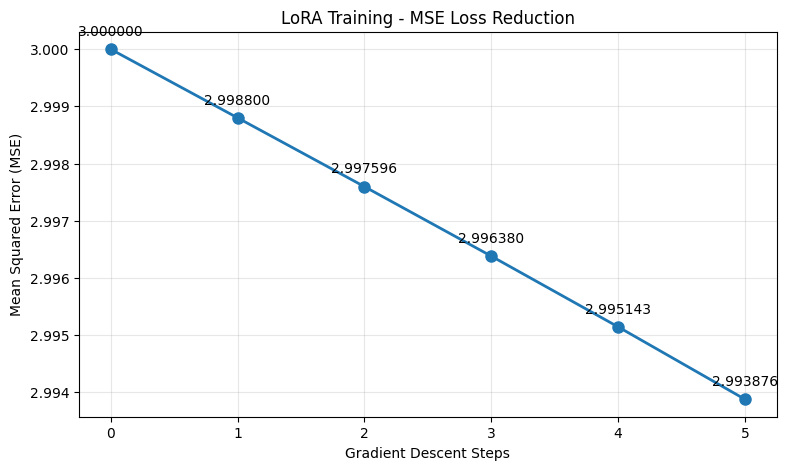

In [ ]:
# TASK (d): VISUALIZE TRAINING LOSS

import matplotlib.pyplot as plt

steps = list(range(len(loss_history)))

plt.figure(figsize=(9, 5))

plt.plot(
    steps,
    loss_history,
    marker="o",
    linewidth=2,
    markersize=8
)

plt.title("LoRA Training - MSE Loss Reduction")
plt.xlabel("Gradient Descent Steps")
plt.ylabel("Mean Squared Error (MSE)")

plt.xticks(steps)
plt.grid(True, alpha=0.3)

for step, loss in zip(steps, loss_history):
    plt.annotate(
        f"{loss:.6f}",
        (step, loss),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

plt.show()

In [ ]:
# TASK (d): OBSERVATION TABLE

print("=" * 45)
print("LoRA TRAINING OBSERVATION TABLE")
print("=" * 45)

print(f"{'Step':<15}{'MSE Loss':<15}")
print("-" * 30)

for step, loss in enumerate(loss_history):
    print(f"{step:<15}{loss:<15.6f}")

print("-" * 30)
print("Initial Loss:", round(loss_history[0], 6))
print("Final Loss  :", round(loss_history[-1], 6))

LoRA TRAINING OBSERVATION TABLE
Step           MSE Loss       
------------------------------
0              3.000000       
1              2.998800       
2              2.997596       
3              2.996380       
4              2.995143       
5              2.993876       
------------------------------
Initial Loss: 3.0
Final Loss  : 2.993876


In [ ]:
# SET A - Q3
# TASK (e): PARAMETER COUNT COMPARISON

print("=" * 60)
print("TASK (e): FULL FINE-TUNING VS LoRA")
print("=" * 60)

# Count full fine-tuning parameters
full_parameters = W0.size

# Count LoRA trainable parameters
A_parameters = A.size
B_parameters = B.size

lora_parameters = A_parameters + B_parameters

# Calculate reduction
parameters_saved = full_parameters - lora_parameters

reduction_percentage = (
    parameters_saved / full_parameters
) * 100

print("\nFULL FINE-TUNING")
print("Trainable Parameters:", full_parameters)

print("\nLoRA FINE-TUNING")
print("A Parameters:", A_parameters)
print("B Parameters:", B_parameters)
print("Total Trainable Parameters:", lora_parameters)

print("\nPARAMETER COMPARISON")
print("Parameters Saved:", parameters_saved)
print(f"Parameter Reduction: {reduction_percentage:.2f}%")

print("\nNOTE:")
print("W0 remains frozen during LoRA training.")
print("Only A and B are updated.")

TASK (e): FULL FINE-TUNING VS LoRA

FULL FINE-TUNING
Trainable Parameters: 16

LoRA FINE-TUNING
A Parameters: 4
B Parameters: 4
Total Trainable Parameters: 8

PARAMETER COMPARISON
Parameters Saved: 8
Parameter Reduction: 50.00%

NOTE:
W0 remains frozen during LoRA training.
Only A and B are updated.


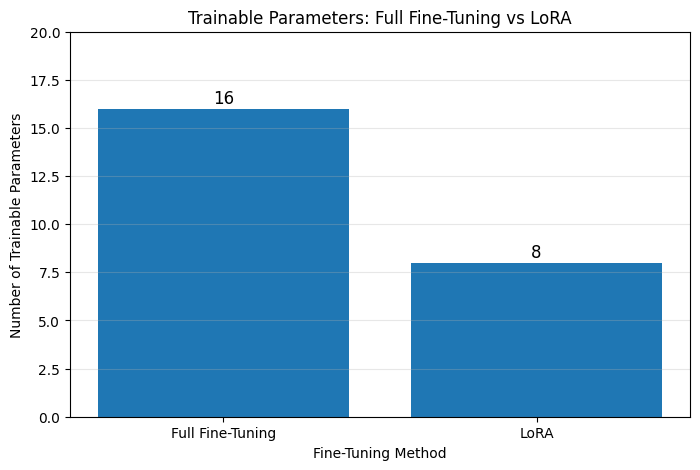

In [ ]:
# TASK (e): PARAMETER COMPARISON GRAPH

import matplotlib.pyplot as plt

methods = ["Full Fine-Tuning", "LoRA"]
parameters = [full_parameters, lora_parameters]

plt.figure(figsize=(8, 5))

bars = plt.bar(methods, parameters)

for bar, value in zip(bars, parameters):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        str(value),
        ha="center",
        fontsize=12
    )

plt.title("Trainable Parameters: Full Fine-Tuning vs LoRA")
plt.xlabel("Fine-Tuning Method")
plt.ylabel("Number of Trainable Parameters")

plt.ylim(0, 20)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
# FINAL VERIFICATION - SET A Q3

print("=" * 60)
print("SET A - Q3: FINAL VERIFICATION")
print("=" * 60)

# Verify original weights are unchanged
assert np.array_equal(W0, W0_original)

# Verify LoRA matrix shapes
assert A.shape == (4, 1)
assert B.shape == (1, 4)

# Verify adapted weight shape
W_final = W0 + A @ B
assert W_final.shape == (4, 4)

# Verify exactly 5 training updates
assert len(loss_history) == 6

# Verify loss decreased
assert loss_history[-1] < loss_history[0]

# Verify trainable parameters
assert full_parameters == 16
assert lora_parameters == 8

print("\nALL VERIFICATION CHECKS PASSED!")

print(f"\nInitial Loss: {loss_history[0]:.6f}")
print(f"Final Loss  : {loss_history[-1]:.6f}")

print("\nW0 Frozen:", np.array_equal(W0, W0_original))

print("\nFull Fine-Tuning Parameters:", full_parameters)
print("LoRA Trainable Parameters:", lora_parameters)

print(f"\nParameter Reduction: {reduction_percentage:.2f}%")

print("\nQ3 IMPLEMENTATION COMPLETED SUCCESSFULLY!")

SET A - Q3: FINAL VERIFICATION

ALL VERIFICATION CHECKS PASSED!

Initial Loss: 3.000000
Final Loss  : 2.993876

W0 Frozen: True

Full Fine-Tuning Parameters: 16
LoRA Trainable Parameters: 8

Parameter Reduction: 50.00%

Q3 IMPLEMENTATION COMPLETED SUCCESSFULLY!


In [ ]:
import numpy as np

# Given documents
docs = [
    "mildew affects tomatoes",
    "mildew affects potatoes",
    "sun affects tomatoes",
    "tomatoes grow in sun and rain",
    "potatoes need sun"
]

query = "mildew tomatoes"

# Remove specified stopwords
stopwords = {"and", "in"}

tokenized_docs = [
    [word for word in doc.lower().split()
     if word not in stopwords]
    for doc in docs
]

# Create vocabulary
vocab = sorted(set(
    word
    for doc in tokenized_docs
    for word in doc
))

print("VOCABULARY:")
print(vocab)

print("\nVocabulary Size:", len(vocab))

# Create one-hot matrix
one_hot = np.eye(len(vocab), dtype=int)

print("\nONE-HOT ENCODING:")
for word, vector in zip(vocab, one_hot):
    print(f"{word:12s} -> {vector}")

print("\nOne-Hot Matrix Shape:", one_hot.shape)

VOCABULARY:
['affects', 'grow', 'mildew', 'need', 'potatoes', 'rain', 'sun', 'tomatoes']

Vocabulary Size: 8

ONE-HOT ENCODING:
affects      -> [1 0 0 0 0 0 0 0]
grow         -> [0 1 0 0 0 0 0 0]
mildew       -> [0 0 1 0 0 0 0 0]
need         -> [0 0 0 1 0 0 0 0]
potatoes     -> [0 0 0 0 1 0 0 0]
rain         -> [0 0 0 0 0 1 0 0]
sun          -> [0 0 0 0 0 0 1 0]
tomatoes     -> [0 0 0 0 0 0 0 1]

One-Hot Matrix Shape: (8, 8)


In [ ]:
# ============================================
# TEXT REPRESENTATION 2: BAG-OF-WORDS (BoW)
# NumPy Only - No sklearn
# ============================================

import numpy as np

# Task 1: Create an empty BoW matrix
num_docs = len(tokenized_docs)
vocab_size = len(vocab)

bow_matrix = np.zeros(
    (num_docs, vocab_size),
    dtype=int
)

# Task 2: Count each vocabulary word
for i, doc in enumerate(tokenized_docs):
    for j, word in enumerate(vocab):
        bow_matrix[i, j] = doc.count(word)

# Task 3: Display results
print("=" * 60)
print("BAG-OF-WORDS TEXT REPRESENTATION")
print("=" * 60)

print("\nVocabulary:")
print(vocab)

print("\nBag-of-Words Matrix:")
print(bow_matrix)

print("\nMatrix Shape:", bow_matrix.shape)

print("\nDOCUMENT-WISE REPRESENTATION")

for i, vector in enumerate(bow_matrix):
    print(f"D{i+1}: {vector}")

BAG-OF-WORDS TEXT REPRESENTATION

Vocabulary:
['affects', 'grow', 'mildew', 'need', 'potatoes', 'rain', 'sun', 'tomatoes']

Bag-of-Words Matrix:
[[1 0 1 0 0 0 0 1]
 [1 0 1 0 1 0 0 0]
 [1 0 0 0 0 0 1 1]
 [0 1 0 0 0 1 1 1]
 [0 0 0 1 1 0 1 0]]

Matrix Shape: (5, 8)

DOCUMENT-WISE REPRESENTATION
D1: [1 0 1 0 0 0 0 1]
D2: [1 0 1 0 1 0 0 0]
D3: [1 0 0 0 0 0 1 1]
D4: [0 1 0 0 0 1 1 1]
D5: [0 0 0 1 1 0 1 0]


In [ ]:
# Demonstrating the limitation of Bag-of-Words

sentence1 = "mildew affects tomatoes"
sentence2 = "tomatoes affects mildew"

def create_bow(sentence, vocab):
    words = sentence.lower().split()

    return np.array([
        words.count(word) for word in vocab
    ])

vector1 = create_bow(sentence1, vocab)
vector2 = create_bow(sentence2, vocab)

print("Sentence 1:", sentence1)
print("BoW Vector 1:", vector1)

print("\nSentence 2:", sentence2)
print("BoW Vector 2:", vector2)

print("\nAre the vectors identical?")
print(np.array_equal(vector1, vector2))

Sentence 1: mildew affects tomatoes
BoW Vector 1: [1 0 1 0 0 0 0 1]

Sentence 2: tomatoes affects mildew
BoW Vector 2: [1 0 1 0 0 0 0 1]

Are the vectors identical?
True


In [ ]:
# ============================================
# TEXT REPRESENTATION 4: N-GRAMS
# ============================================

# Task 1: Create N-Gram function

def generate_ngrams(tokens, n):

    ngrams = []

    for i in range(len(tokens) - n + 1):
        gram = tuple(tokens[i:i+n])
        ngrams.append(gram)

    return ngrams


# Task 2: Select a sentence
sentence = "mildew affects tomatoes"
tokens = sentence.lower().split()

# Task 3: Generate N-Grams
unigrams = generate_ngrams(tokens, 1)
bigrams = generate_ngrams(tokens, 2)
trigrams = generate_ngrams(tokens, 3)

print("N-GRAM TEXT REPRESENTATION")
print("=" * 45)

print("Sentence:", sentence)

print("\nUnigrams:", unigrams)
print("Bigrams:", bigrams)
print("Trigrams:", trigrams)

print("\nNumber of Unigrams:", len(unigrams))
print("Number of Bigrams:", len(bigrams))
print("Number of Trigrams:", len(trigrams))

N-GRAM TEXT REPRESENTATION
Sentence: mildew affects tomatoes

Unigrams: [('mildew',), ('affects',), ('tomatoes',)]
Bigrams: [('mildew', 'affects'), ('affects', 'tomatoes')]
Trigrams: [('mildew', 'affects', 'tomatoes')]

Number of Unigrams: 3
Number of Bigrams: 2
Number of Trigrams: 1


In [ ]:
# Task 4: Generate N-Grams for all documents

print("N-GRAMS FOR ALL DOCUMENTS")
print("=" * 55)

for i, tokens in enumerate(tokenized_docs, start=1):

    print(f"\nDOCUMENT {i}:")
    print("Tokens:", tokens)

    for n in [1, 2, 3]:

        grams = generate_ngrams(tokens, n)

        readable_grams = [
            " ".join(gram) for gram in grams
        ]

        print(f"{n}-Grams:", readable_grams)
        print(f"Count: {len(grams)}")

N-GRAMS FOR ALL DOCUMENTS

DOCUMENT 1:
Tokens: ['mildew', 'affects', 'tomatoes']
1-Grams: ['mildew', 'affects', 'tomatoes']
Count: 3
2-Grams: ['mildew affects', 'affects tomatoes']
Count: 2
3-Grams: ['mildew affects tomatoes']
Count: 1

DOCUMENT 2:
Tokens: ['mildew', 'affects', 'potatoes']
1-Grams: ['mildew', 'affects', 'potatoes']
Count: 3
2-Grams: ['mildew affects', 'affects potatoes']
Count: 2
3-Grams: ['mildew affects potatoes']
Count: 1

DOCUMENT 3:
Tokens: ['sun', 'affects', 'tomatoes']
1-Grams: ['sun', 'affects', 'tomatoes']
Count: 3
2-Grams: ['sun affects', 'affects tomatoes']
Count: 2
3-Grams: ['sun affects tomatoes']
Count: 1

DOCUMENT 4:
Tokens: ['tomatoes', 'grow', 'sun', 'rain']
1-Grams: ['tomatoes', 'grow', 'sun', 'rain']
Count: 4
2-Grams: ['tomatoes grow', 'grow sun', 'sun rain']
Count: 3
3-Grams: ['tomatoes grow sun', 'grow sun rain']
Count: 2

DOCUMENT 5:
Tokens: ['potatoes', 'need', 'sun']
1-Grams: ['potatoes', 'need', 'sun']
Count: 3
2-Grams: ['potatoes need', 'need 

In [ ]:
# Task 5: Compare BoW and N-Grams

sentence1 = "mildew affects tomatoes"
sentence2 = "tomatoes affects mildew"

tokens1 = sentence1.split()
tokens2 = sentence2.split()

# Bag-of-Words
bow1 = [tokens1.count(word) for word in vocab]
bow2 = [tokens2.count(word) for word in vocab]

# Bigrams
bigrams1 = generate_ngrams(tokens1, 2)
bigrams2 = generate_ngrams(tokens2, 2)

print("SENTENCE 1:", sentence1)
print("BoW:", bow1)
print("Bigrams:", bigrams1)

print("\nSENTENCE 2:", sentence2)
print("BoW:", bow2)
print("Bigrams:", bigrams2)

print("\nAre BoW vectors identical?", bow1 == bow2)

print("Are Bigrams identical?", bigrams1 == bigrams2)

SENTENCE 1: mildew affects tomatoes
BoW: [1, 0, 1, 0, 0, 0, 0, 1]
Bigrams: [('mildew', 'affects'), ('affects', 'tomatoes')]

SENTENCE 2: tomatoes affects mildew
BoW: [1, 0, 1, 0, 0, 0, 0, 1]
Bigrams: [('tomatoes', 'affects'), ('affects', 'mildew')]

Are BoW vectors identical? True
Are Bigrams identical? False


In [ ]:
# ============================================
# TEXT REPRESENTATION 5: CO-OCCURRENCE MATRIX
# Using NumPy Only
# ============================================

import numpy as np

# Task 1: Define context window
window_size = 1

# Task 2: Create empty co-occurrence matrix
vocab_size = len(vocab)

co_matrix = np.zeros(
    (vocab_size, vocab_size),
    dtype=int
)

# Create word-to-index mapping
word_to_index = {
    word: i for i, word in enumerate(vocab)
}

# Task 3: Count neighboring words
for doc in tokenized_docs:

    for i, target_word in enumerate(doc):

        target_index = word_to_index[target_word]

        start = max(0, i - window_size)
        end = min(len(doc), i + window_size + 1)

        for j in range(start, end):

            # Do not count the target word itself
            if i == j:
                continue

            context_word = doc[j]
            context_index = word_to_index[context_word]

            co_matrix[target_index, context_index] += 1

# Task 4: Display matrix
print("CO-OCCURRENCE MATRIX")
print("=" * 60)

print("\nVocabulary:")
print(vocab)

print("\nContext Window Size:", window_size)

print("\nCo-occurrence Matrix:")
print(co_matrix)

print("\nMatrix Shape:", co_matrix.shape)

CO-OCCURRENCE MATRIX

Vocabulary:
['affects', 'grow', 'mildew', 'need', 'potatoes', 'rain', 'sun', 'tomatoes']

Context Window Size: 1

Co-occurrence Matrix:
[[0 0 2 0 1 0 1 2]
 [0 0 0 0 0 0 1 1]
 [2 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 1 0]
 [1 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 1 0]
 [1 1 0 1 0 1 0 0]
 [2 1 0 0 0 0 0 0]]

Matrix Shape: (8, 8)


In [ ]:
# STEP 2: UNDERSTAND WORD RELATIONSHIPS

word1 = "mildew"
word2 = "affects"

i = word_to_index[word1]
j = word_to_index[word2]

print("TARGET WORD:", word1)
print("CONTEXT WORD:", word2)

print(
    "Co-occurrence Count:",
    co_matrix[i, j]
)

print("\nCo-occurrence Vector for 'mildew':")
print(co_matrix[i])

print("\nIs Matrix Symmetric?")
print(np.array_equal(co_matrix, co_matrix.T))

TARGET WORD: mildew
CONTEXT WORD: affects
Co-occurrence Count: 2

Co-occurrence Vector for 'mildew':
[2 0 0 0 0 0 0 0]

Is Matrix Symmetric?
True


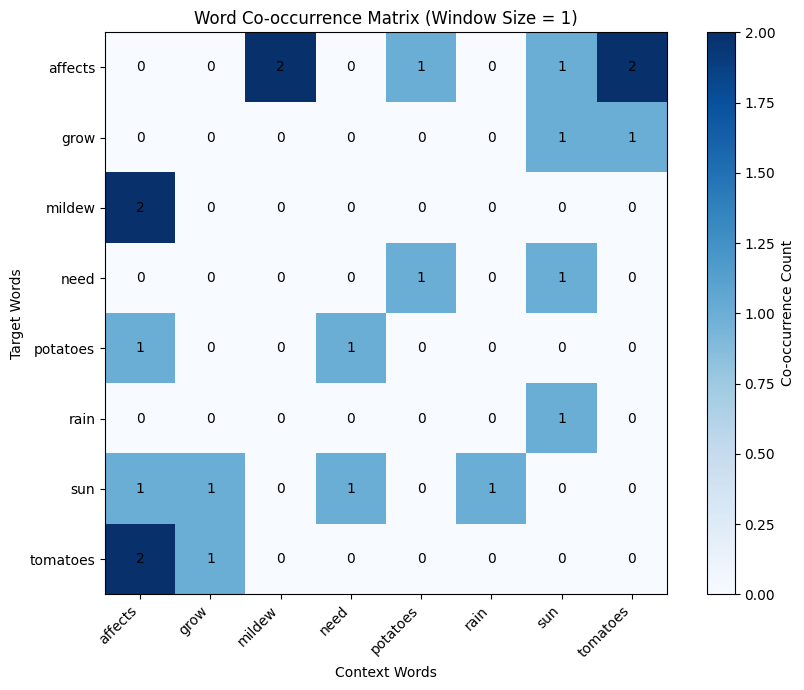

In [ ]:
# STEP 3: CO-OCCURRENCE HEATMAP

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

plt.imshow(co_matrix, cmap="Blues")

plt.xticks(
    range(len(vocab)),
    vocab,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(vocab)),
    vocab
)

# Show counts inside cells
for i in range(len(vocab)):
    for j in range(len(vocab)):
        plt.text(
            j, i,
            str(co_matrix[i, j]),
            ha="center",
            va="center"
        )

plt.title("Word Co-occurrence Matrix (Window Size = 1)")
plt.xlabel("Context Words")
plt.ylabel("Target Words")

plt.colorbar(label="Co-occurrence Count")
plt.tight_layout()
plt.show()

In [ ]:
# STEP 4: COMPARISON OF CONTEXT WINDOWS

def build_cooccurrence(documents, vocabulary, window):

    word_index = {
        word: i for i, word in enumerate(vocabulary)
    }

    matrix = np.zeros(
        (len(vocabulary), len(vocabulary)),
        dtype=int
    )

    for doc in documents:
        for i, word in enumerate(doc):

            start = max(0, i - window)
            end = min(len(doc), i + window + 1)

            for j in range(start, end):
                if i != j:
                    matrix[
                        word_index[word],
                        word_index[doc[j]]
                    ] += 1

    return matrix


for window in [1, 2, 3]:

    matrix = build_cooccurrence(
        tokenized_docs,
        vocab,
        window
    )

    print(f"\nWINDOW SIZE = {window}")
    print(matrix)
    print("Total Co-occurrence Counts:", matrix.sum())


WINDOW SIZE = 1
[[0 0 2 0 1 0 1 2]
 [0 0 0 0 0 0 1 1]
 [2 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 1 0]
 [1 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 1 0]
 [1 1 0 1 0 1 0 0]
 [2 1 0 0 0 0 0 0]]
Total Co-occurrence Counts: 22

WINDOW SIZE = 2
[[0 0 2 0 1 0 1 2]
 [0 0 0 0 0 1 1 1]
 [2 0 0 0 1 0 0 1]
 [0 0 0 0 1 0 1 0]
 [1 0 1 1 0 0 1 0]
 [0 1 0 0 0 0 1 0]
 [1 1 0 1 1 1 0 2]
 [2 1 1 0 0 0 2 0]]
Total Co-occurrence Counts: 34

WINDOW SIZE = 3
[[0 0 2 0 1 0 1 2]
 [0 0 0 0 0 1 1 1]
 [2 0 0 0 1 0 0 1]
 [0 0 0 0 1 0 1 0]
 [1 0 1 1 0 0 1 0]
 [0 1 0 0 0 0 1 1]
 [1 1 0 1 1 1 0 2]
 [2 1 1 0 0 1 2 0]]
Total Co-occurrence Counts: 36


In [ ]:
# ============================================
# TEXT REPRESENTATION 6: WORD EMBEDDINGS
# USING SINGULAR VALUE DECOMPOSITION (SVD)
# NumPy Only
# ============================================

import numpy as np

# Task 1: Use the existing co-occurrence matrix
M = co_matrix.astype(float)

print("ORIGINAL CO-OCCURRENCE MATRIX")
print(M)

print("\nOriginal Shape:", M.shape)

# Task 2: Apply SVD
U, S, VT = np.linalg.svd(M, full_matrices=False)

print("\nSINGULAR VALUES:")
print(np.round(S, 3))

# Task 3: Select 3 dimensions
embedding_dim = 3

# Task 4: Create dense word embeddings
word_embeddings = (
    U[:, :embedding_dim]
    * np.sqrt(S[:embedding_dim])
)

print("\nDENSE WORD EMBEDDINGS:")
for word, vector in zip(vocab, word_embeddings):
    print(f"{word:12s} -> {np.round(vector, 3)}")

print("\nOriginal Dimension:", M.shape[1])
print("Reduced Dimension:", embedding_dim)

print("\nEmbedding Matrix Shape:", word_embeddings.shape)

ORIGINAL CO-OCCURRENCE MATRIX
[[0. 0. 2. 0. 1. 0. 1. 2.]
 [0. 0. 0. 0. 0. 0. 1. 1.]
 [2. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 1. 0.]
 [1. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0.]
 [1. 1. 0. 1. 0. 1. 0. 0.]
 [2. 1. 0. 0. 0. 0. 0. 0.]]

Original Shape: (8, 8)

SINGULAR VALUES:
[3.423 3.423 1.485 1.485 0.952 0.952 0.413 0.413]

DENSE WORD EMBEDDINGS:
affects      -> [ 0.    -1.681  0.459]
grow         -> [ 0.    -0.589 -0.433]
mildew       -> [-0.982 -0.     0.001]
need         -> [ 0.    -0.433 -0.813]
potatoes     -> [-0.617 -0.    -0.   ]
rain         -> [ 0.    -0.252 -0.653]
sun          -> [-0.863 -0.    -0.001]
tomatoes     -> [-1.154  0.     0.   ]

Original Dimension: 8
Reduced Dimension: 3

Embedding Matrix Shape: (8, 3)


In [ ]:
# ============================================
# TASK: WORD EMBEDDING SIMILARITY
# ============================================

# Create word-to-index mapping
embedding_index = {
    word: i for i, word in enumerate(vocab)
}

def word_similarity(word1, word2):

    v1 = word_embeddings[embedding_index[word1]]
    v2 = word_embeddings[embedding_index[word2]]

    numerator = np.dot(v1, v2)

    denominator = (
        np.linalg.norm(v1) *
        np.linalg.norm(v2)
    )

    if denominator == 0:
        return 0.0

    return numerator / denominator


# Compare words
word1 = "tomatoes"
word2 = "potatoes"

similarity = word_similarity(word1, word2)

print("WORD EMBEDDING SIMILARITY")
print("=" * 45)

print("Word 1:", word1)
print("Word 2:", word2)

print("\nEmbedding 1:")
print(np.round(word_embeddings[embedding_index[word1]], 3))

print("\nEmbedding 2:")
print(np.round(word_embeddings[embedding_index[word2]], 3))

print(f"\nCosine Similarity: {similarity:.3f}")

WORD EMBEDDING SIMILARITY
Word 1: tomatoes
Word 2: potatoes

Embedding 1:
[-1.154  0.     0.   ]

Embedding 2:
[-0.617 -0.    -0.   ]

Cosine Similarity: 1.000


In [ ]:
# ==================================================
# TEXT REPRESENTATION 7: CONTEXTUAL EMBEDDINGS
# USING SELF-ATTENTION
# NumPy Only
# ==================================================

import numpy as np

# TASK 1: Define sentences
sentence1 = "mildew affects tomatoes"
sentence2 = "mildew affects potatoes"

print("TEXT REPRESENTATION: CONTEXTUAL EMBEDDINGS")
print("=" * 55)

print("Sentence 1:", sentence1)
print("Sentence 2:", sentence2)

# TASK 2: Create word-to-index dictionary
word_index = {
    word: i for i, word in enumerate(vocab)
}

# TASK 3: Define softmax function
def softmax(scores):
    exp_scores = np.exp(scores - np.max(scores, axis=-1, keepdims=True))
    return exp_scores / np.sum(exp_scores, axis=-1, keepdims=True)

# TASK 4: Define self-attention function
def self_attention(sentence, target_word="affects"):

    tokens = sentence.lower().split()

    # Convert words into static embedding vectors
    X = np.array([
        word_embeddings[word_index[word]]
        for word in tokens
    ])

    # Identity projections: Q = K = V = X
    Q = X
    K = X
    V = X

    # Calculate scaled dot-product scores
    d_k = K.shape[1]
    scores = (Q @ K.T) / np.sqrt(d_k)

    # Calculate attention weights
    weights = softmax(scores)

    # Compute contextual representations
    contextual_vectors = weights @ V

    # Find target word
    target_position = tokens.index(target_word)

    return (
        tokens,
        X[target_position],
        scores[target_position],
        weights[target_position],
        contextual_vectors[target_position]
    )


# TASK 5: Compute contextual embedding for sentence 1
tokens1, static1, scores1, weights1, context1 = self_attention(sentence1)

# TASK 6: Compute contextual embedding for sentence 2
tokens2, static2, scores2, weights2, context2 = self_attention(sentence2)

np.set_printoptions(precision=3, suppress=True)

print("\nSENTENCE 1 RESULTS")
print("-" * 45)
print("Tokens:", tokens1)
print("Static Embedding:", np.round(static1, 3))
print("Scaled Scores:", np.round(scores1, 3))
print("Attention Weights:", np.round(weights1, 3))
print("Contextual Embedding:", np.round(context1, 3))

print("\nSENTENCE 2 RESULTS")
print("-" * 45)
print("Tokens:", tokens2)
print("Static Embedding:", np.round(static2, 3))
print("Scaled Scores:", np.round(scores2, 3))
print("Attention Weights:", np.round(weights2, 3))
print("Contextual Embedding:", np.round(context2, 3))

print("\nFINAL COMPARISON")
print("-" * 45)

print("Are static embeddings identical?")
print(np.allclose(static1, static2))

print("Are contextual embeddings identical?")
print(np.allclose(context1, context2))

print("\nDifference Between Contextual Embeddings:")
print(np.round(context1 - context2, 3))

TEXT REPRESENTATION: CONTEXTUAL EMBEDDINGS
Sentence 1: mildew affects tomatoes
Sentence 2: mildew affects potatoes

SENTENCE 1 RESULTS
---------------------------------------------
Tokens: ['mildew', 'affects', 'tomatoes']
Static Embedding: [ 0.    -1.681  0.459]
Scaled Scores: [0.    1.753 0.   ]
Attention Weights: [0.129 0.743 0.129]
Contextual Embedding: [-0.275 -1.248  0.341]

SENTENCE 2 RESULTS
---------------------------------------------
Tokens: ['mildew', 'affects', 'potatoes']
Static Embedding: [ 0.    -1.681  0.459]
Scaled Scores: [ 0.     1.753 -0.   ]
Attention Weights: [0.129 0.743 0.129]
Contextual Embedding: [-0.206 -1.248  0.341]

FINAL COMPARISON
---------------------------------------------
Are static embeddings identical?
True
Are contextual embeddings identical?
False

Difference Between Contextual Embeddings:
[-0.069  0.     0.   ]


In [ ]:
# ==========================================
# FINAL VERIFICATION
# ==========================================

print("CONTEXTUAL EMBEDDING VERIFICATION")
print("=" * 50)

# Verify static embedding is identical
assert np.allclose(static1, static2)

# Verify attention weights are normalized
assert np.isclose(np.sum(weights1), 1.0)
assert np.isclose(np.sum(weights2), 1.0)

# Verify output dimensions
assert context1.shape == static1.shape
assert context2.shape == static2.shape

print("PASS: Static embeddings are identical.")
print("PASS: Attention weights sum to 1.")
print("PASS: Contextual embeddings have correct dimensions.")

if not np.allclose(context1, context2):
    print("PASS: Contextual representations differ.")
else:
    print("NOTE: Contextual vectors are nearly identical for this tiny dataset.")

print("\nCONTEXTUAL EMBEDDING IMPLEMENTATION COMPLETED!")

CONTEXTUAL EMBEDDING VERIFICATION
PASS: Static embeddings are identical.
PASS: Attention weights sum to 1.
PASS: Contextual embeddings have correct dimensions.
PASS: Contextual representations differ.

CONTEXTUAL EMBEDDING IMPLEMENTATION COMPLETED!
